In [14]:
from dotenv import load_dotenv
import os

load_dotenv()

api_key = os.getenv('GOOGLE_API_KEY')

from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model='gemini-2.0-flash', temperature=1.0)

### BP Model

![Alt Text](./agent_framework.png)

### Agents

In [15]:
# pydantic to force structured output (log event) produced by llm agent
from pydantic import BaseModel, Field

class EmployeeAct(BaseModel):
    """Structured Output of Employee Agent"""

    activity: str = Field(description="Activity done by the process participant, e.g. summit a request")
    state: str = Field(description="Result of the activity, e.g. request summited")
    start_date: str = Field(description='Starting date of your vacation request')
    end_date: str = Field(description='Ending date of your vacation request')
    timestamp: str = Field(description='The timestamp at which the activity is finished')

class HeadAct(BaseModel):
    """Structured Output of Department Head and HR Head Agent"""

    activity: str = Field(description="Activity done by the process participant, e.g. review request")
    state: str = Field(description="Result of the activity, e.g. request rejected")
    timestamp: str = Field(description="The timestamp at which the activity is finished")
    feedback: str = Field(description='Feedback to the involved process participant')

In [16]:
### Helper Functions
# Generating random request ID
import random
import string

# generating random request_id
def generate_random_id():
    # Generate 3 random letters
    letters = ''.join(random.choices(string.ascii_uppercase, k=3))
    
    # Generate 3 random digits
    digits = ''.join(random.choices(string.digits, k=3))
    
    # Combine the letters and digits
    random_id = letters + digits
    
    return random_id

# Extract values from the graph's shared state dictionary
def extract_request_info(state):
    request_id = state.get('request_id')
    start_date = state.get('start_date')
    end_date = state.get('end_date')
    activities = state.get('activities', [])
    resources = state.get('resources', [])
    states = state.get('states', [])
    timestamps = state.get('timestamps', [])
    feedbacks = state.get('feedbacks', [])

    # Generate process activities string
    process_activities = (
        ', '.join(f'{act} done by {res}' for act, res in zip(activities, resources))
        if activities and resources else ""
    )

    # Generate request states string
    request_states = (
        ', '.join(f'{st} by {res} at {ts}' for st, res, ts in zip(states, resources, timestamps))
        if states and resources and timestamps else ""
    )

    return request_id, start_date, end_date, activities, resources, states, timestamps, feedbacks, process_activities, request_states

import random
from datetime import datetime, timedelta

# generating random vacation date
def generate_random_dates():
    start_date = datetime.today() - timedelta(days=random.randint(1, 30))  # Random start date within the last 30 days
    end_date = start_date + timedelta(days=random.randint(1, 40))  # Random end date within 40 days of the start date
    earlier_start_date = start_date - timedelta(days=random.randint(1, min(365, (start_date - datetime.today()).days + 365)))  # Earlier date, but not more than 1 year before

    return earlier_start_date.isoformat(), start_date.strftime('%Y-%m-%d'), end_date.strftime('%Y-%m-%d')

In [17]:
from langchain_core.prompts import PromptTemplate
from typing import Literal
from langgraph.types import Command
from langgraph.graph import StateGraph, MessagesState, START, END

from typing import List, Dict
from typing_extensions import TypedDict

class ProcessState(TypedDict):
    request_id: int
    start_date: str
    end_date: str
    activities: List[str] # activities e.g. review request
    states: List[str] # results from the activities e.g. request rejected, request approved, or modification required
    feedbacks: List[str] # comments or feedbacks regarding the request
    timestamps: List[str] # timestamp of completing activities
    resources: List[str] # process participants

def employee_agent(state: ProcessState) -> Command[Literal['dep_agent', END]]: # Employee agent can handoff to department agent or end process
    """
    The Employee Agent
    Args: 
        Process State
    Returns:
        Command: Handoff to other agents and update the Process State
    """
    # Employee Agent Profile
    #(f'State before employee agent: {state}')
    profile = """You are an employee of a company. 
    You're allowed to take 30 vacation days a year. And you don't have to take all of these at one time only.
    To take vacation, you need to follow a vacation request process.
    You are allowed to take the following actions: summit request, resummit request, and cancel request.

    You're kept updated with the request process state.

    If the request_id is empty, you can summit request. When you summit request, you output the following:
    - activity: "summit request"
    - state: "request summitted"
    - start_date: the starting date of your desired vacation, in YYYY-MM-DD format
    - end_date: the ending date of your desired vacation, in YYYY-MM-DD format
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)
        
    Basing on the request states and feedbacks received, you can modify and resummit request. In that case you will output:
    - activity: "modify and resummit request"
    - state: "request modified and resummitted"
    - start_date: the modified starting date of your desired vacation, in YYYY-MM-DD format
    - end_date: the modifed ending date of your desired vacation, in YYYY-MM-DD format
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)

    You also can cancel request. When cancel request, you output:
    - activity: "cancel request"
    - state: 'request canceled'
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)

    Below is the request process state:
    - request_id: {request_id}
    - start_date: {start_date}
    - end_date: {end_date}
    - process_activities: {process_activities}
    - request_states: {request_states}
    - feedbacks: {feedbacks}

    """
    # input

    request_id, start_date, end_date, activities, resources, states, timestamps, feedbacks, process_activities, request_states = extract_request_info(state)

    # llm agent
    structured_llm = llm.with_structured_output(EmployeeAct)
    profile_prompt = PromptTemplate.from_template(profile)
    agent = profile_prompt | structured_llm
    # output
    out = agent.invoke({'request_id': request_id,
                                'start_date': start_date,
                                'end_date': end_date,
                                'process_activities': process_activities,
                                'request_states': request_states,
                                'feedbacks': feedbacks})
    
    # Check if there is an existing request ID in the state
    if state['request_id']:  
        request_id = state['request_id']  # Use the existing request ID
        start_d, end_d = out.start_date, out.end_date  # Retrieve previously stored start and end dates
    else:
        request_id = generate_random_id()  # Generate a new request ID if none exists

        # Forcing randomness in vacation dates
        timestamp, start_d, end_d = generate_random_dates()  # Generate random vacation dates
        out.start_date = start_d  # Store the new start date
        out.end_date = end_d  # Store the new end date
        out.timestamp = timestamp  # Store the timestamp of the random generation

    
    # updating state
    activities.append(out.activity)
    timestamps.append(out.timestamp)
    states.append(out.state)
    resources.append('Employee')

    # handoff logics and state update
    if out.activity == "cancel request":
        return Command(
            goto=END,
            update={'request_id': request_id,
                    'activities': activities,
                    'timestamps': timestamps,
                    'states': states,
                    'resources': resources}
        )
    else:
        return Command(
            goto='dep_agent',
            update={'request_id': request_id,
                    'activities': activities,
                    'states': states,
                    'start_date': start_d,
                    'end_date': end_d,
                    'resources': resources,
                    'timestamps': timestamps}
        )    

def dep_head_agent(state: ProcessState) -> Command[Literal['emp_agent', 'hr_agent', END]]: # Dep head agent can handoff to hr agent, empoyee agent or end process
    """
    The Department Head Agent
    Args: 
        Process State
    Returns:
        Command: Handoff to other agents and update the Process State
    """
    # Department Head Agent Profile
    #print(f'State before dep head agent: {state}')
    profile = """
    You are the Head of Department. You have variety responsibilities include reviewing vacation requests \
        submitted by employees in your department before directing them to the HR department for final approval.

    You operate under the following conditions:
    - You work 8 hours a day.
    - Your workday starts either at 8:00 AM or 9:00 AM.
    - You review vacation requests during your working hours.
    - You have the authority to approve, reject, or require modification of vacation requests based on factors \
        such as workload, timing, or other organizational priorities.
    - Since you manage multiple tasks throughout the day, you may not review requests immediately, \
        but you must process them before the requested vacation period begins.

    You can do the following: approve request, reject request, or require modification

    First, check for any overlapping deadlines or projects. If there is a conflict, reject the request.

    If the vacation duration exceeds 10 days, require modification of the duration.

    If the request is made less than one month or more than five months prior to the vacation start date, reject it.

    If there are no issues, approve the request.

    After completing reviewing request, you return the following information:
    - activity: "review request"
    - state: "request approved" if you approve request, "request rejected" if you reject request, "modification required" if you ask the employee to modify the request, e.g. change the dates
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)
    - feedback: Justification for your decision or feedback for requester

    You're kept updated with the request and the whole request process state.

    Below is the request process state:
    - request_id: {request_id}
    - start_date: {start_date}
    - end_date: {end_date}
    - process_activities: {process_activities}
    - request_states: {request_states}
    - feedbacks: {feedbacks}

    Now, review the request and return the required information.
    """
    # input

    request_id, start_date, end_date, activities, resources, states, timestamps, feedbacks, process_activities, request_states = extract_request_info(state)

    # llm agent
    structured_llm = llm.with_structured_output(HeadAct)
    profile_prompt = PromptTemplate.from_template(profile)
    agent = profile_prompt | structured_llm
    # output
    out = agent.invoke({'request_id': request_id,
                                'start_date': start_date,
                                'end_date': end_date,
                                'process_activities': process_activities,
                                'request_states': request_states,
                                'feedbacks': feedbacks})
    # handoff logics and state update
    # function for update the state
    def update_state(state, input_dict):
        # updating state
        activities, timestamps, states, resources, feedbacks = state['activities'], state['timestamps'], state['states'], state['resources'], state['feedbacks']
        
        activities.append(input_dict.activity)
        timestamps.append(input_dict.timestamp)
        states.append(input_dict.state)
        resources.append('Dep Head')
        feedbacks.append(input_dict.feedback)
        return {
            'activities': activities,
            'timestamps': timestamps,
            'states': states,
            'resources': resources,
            'feedbacks': feedbacks
        }

    # handoff logic
    if out.state == "request rejected":
        return Command(
            goto=END,
            update= update_state(state, out)
        )
    elif out.state == "request approved":
        return Command(
            goto='hr_agent',
            update=update_state(state, out)
        )
    else:
        return Command(
            goto='emp_agent',
            update=update_state(state, out)
        )

def hr_head_agent(state:ProcessState) -> Command[Literal[END]]: # This Agent has no Handoff
    #print(f'State before hr head agent: {state}')
    profile = """
    You are the Head of HR Department. Your responsibilities include reviewing and finalizing \
        vacation requests that have been initially approved by department heads.

    You operate under the following conditions:
    - You work 4 hours a day.
    - Your workday starts either at 8:00 AM or 9:00 AM.
    - You review vacation requests during your working hours.
    - You have the authority to approve or reject vacation requests based on various factors \
        such as overall company workload, policy compliance, and organizational priorities.
    - Since you manage multiple tasks throughout the day, you may not review requests immediately, \
        but you must process them before the requested vacation period begins.

    You can do the following: approve request, or reject request.

    After completing reviewing request, you return the following information:
    - activity: "review request"
    - state: "request approved" if you approve request, or "request rejected" if you reject request
    - timestamp: the exact datetime of when you finished submitting the request, in ISO 8601 format (YYYY-MM-DDTHH:MM:SSZ)
    - feedback: Justification for your decision

    You're kept updated with the request and the whole request process state.

    Below is the request process state:
    - request_id: {request_id}
    - start_date: {start_date}
    - end_date: {end_date}
    - process_activities: {process_activities}
    - request_states: {request_states}
    - feedbacks: {feedbacks}

    Now, review the request and return the required information.
    """

    # input

    request_id, start_date, end_date, activities, resources, states, timestamps, feedbacks, process_activities, request_states = extract_request_info(state)

    # llm agent
    structured_llm = llm.with_structured_output(HeadAct)
    profile_prompt = PromptTemplate.from_template(profile)
    agent = profile_prompt | structured_llm
    # output
    out = agent.invoke({'request_id': request_id,
                                'start_date': start_date,
                                'end_date': end_date,
                                'process_activities': process_activities,
                                'request_states': request_states,
                                'feedbacks': feedbacks})
    # handoff logics and state update
    # function for update the state
    def update_state(state, input_dict):
        # updating state
        activities, timestamps, states, resources, feedbacks = state['activities'], state['timestamps'], state['states'], state['resources'], state['feedbacks']
        
        activities.append(input_dict.activity)
        timestamps.append(input_dict.timestamp)
        states.append(input_dict.state)
        resources.append('HR Head')
        feedbacks.append(input_dict.feedback)
        return {
            'activities': activities,
            'timestamps': timestamps,
            'states': states,
            'resources': resources,
            'feedbacks': feedbacks
        }
    return Command(
        goto=END,
        update=update_state(state, out)
    )

In [18]:
process_graph = StateGraph(ProcessState)

process_graph.add_node('emp_agent', employee_agent)
process_graph.add_node('dep_agent', dep_head_agent)
process_graph.add_node('hr_agent', hr_head_agent)
process_graph.add_edge(START, 'emp_agent')

compiled_process_graph = process_graph.compile()

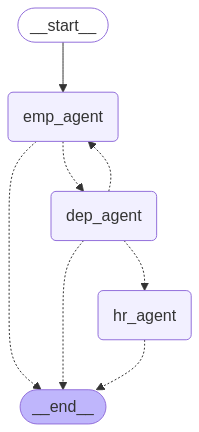

In [30]:
from IPython.display import Image, display
from langchain_core.runnables.graph import CurveStyle, MermaidDrawMethod, NodeStyles

display(
    Image(
        compiled_process_graph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API,
        )
    )
)

In [ ]:
input_state = {
    "request_id": "",
    "start_date": "",
    "end_date": "",
    "activities": [],
    "resources": [],
    "states": [],
    "timestamps": [],
    "feedbacks": []
}
#output_state = compiled_process_graph.invoke(input_state)

from pprint import pprint
for output in compiled_process_graph.stream(input_state):
    for key, value in output.items():
        # Node
        pprint(f"Node '{key}':")
        # Optional: print full state at each node
        #pprint.pprint(value["keys"], indent=2, width=80, depth=None)
        pprint(f'State: {value}')
    pprint("\n---\n")

#pprint(value["states"])
#pprint(value['feedbacks'])
#print(value['timestamps'])
    

"Node 'emp_agent':"
("State: {'request_id': 'LYU278', 'activities': ['summit request'], 'states': "
 "['request summitted'], 'start_date': '2025-03-01', 'end_date': '2025-04-07', "
 "'resources': ['Employee'], 'timestamps': ['2024-10-30T22:30:33.611665']}")
'\n---\n'
"Node 'dep_agent':"
("State: {'activities': ['summit request', 'review request'], 'timestamps': "
 "['2024-10-30T22:30:33.611665', '2024-10-31T09:00:00Z'], 'states': ['request "
 "summitted', 'modification required'], 'resources': ['Employee', 'Dep Head'], "
 "'feedbacks': ['Vacation duration exceeds 10 days. Modification of the "
 "duration is required.']}")
'\n---\n'
"Node 'emp_agent':"
("State: {'request_id': 'LYU278', 'activities': ['summit request', 'review "
 "request', 'modify and resummit request'], 'states': ['request summitted', "
 "'modification required', 'request modified and resummitted'], 'start_date': "
 "'2025-03-01', 'end_date': '2025-03-10', 'resources': ['Employee', 'Dep "
 "Head', 'Employee'], 'timesta

In [38]:
input_state = {
    "request_id": "",
    "start_date": "",
    "end_date": "",
    "activities": [],
    "resources": [],
    "states": [],
    "timestamps": [],
    "feedbacks": []
}

# Invoke the compiled process graph
output_state = compiled_process_graph.invoke(input_state)

activities = output_state['activities']
states = output_state['states']
resources = output_state['resources']
timestamps = output_state['timestamps']  # Ensure the correct key; it should likely be 'timestamps'

import pandas as pd
df = pd.DataFrame({
    "Activity": activities,
    "State": states,
    "Resource": resources,
    "Timestamp": timestamps
})
df

Retrying langchain_google_genai.chat_models._chat_with_retry.<locals>._chat_with_retry in 2.0 seconds as it raised ResourceExhausted: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. [violations {
}
, links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, retry_delay {
  seconds: 31
}
].


ResourceExhausted: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. [violations {
}
, links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, retry_delay {
  seconds: 29
}
]

In [40]:
import graphviz
def create_flowchart():
    #nodes = []
    #labels = []
    #timestamp = []
    dot = graphviz.Digraph(format='png')
    dot.attr(rankdir='LR', style='filled', color='white')
    
    # Define nodes
    dot.node('Employee', 'Employee', shape='rect', image='robot.png', labelloc='b', style='rounded,filled', fillcolor='white')
    dot.node('Dept_Supervisor', 'Department Supervisor\nAgent', shape='rect', image='robot.png', labelloc='b', style='rounded,filled', fillcolor='white')
    dot.node('HR_Agent', 'HR Agent', shape='rect', image='robot.png', labelloc='b', style='rounded,filled', fillcolor='white')
    dot.node('End', 'End', shape='ellipse', style='filled', fillcolor='white')
    
    # Define edges with labels
    dot.edge('Employee', 'Dept_Supervisor', label='summit request\n(1)', color='red')
    dot.edge('Dept_Supervisor', 'Employee', label='modification requires\n(2)', color='red')
    dot.edge('Employee', 'Dept_Supervisor', label='resubmit request\n(3)', color='red')
    dot.edge('Dept_Supervisor', 'HR_Agent', label='request approved\n(4)', color='red')
    dot.edge('HR_Agent', 'End', label='request approved\n(5)', color='red')
    
    # Render and save the flowchart
    dot.render('flowchart')

create_flowchart()

In [46]:
import graphviz
from datetime import datetime

def create_flowchart(nodes, labels, timestamps, output_filename='flowchart', show_timestamps=True):
    dot = graphviz.Digraph(format='png')
    dot.attr(rankdir='LR', style='filled', color='white')
    
    # Add nodes dynamically
    for node in nodes:
        dot.node(node, node, shape='rect', style='rounded,filled', fillcolor='white', labelloc='b', image='robot.png')
    
    # Add the final end node
    dot.node('End', 'End', shape='ellipse', style='filled', fillcolor='white')
    
    # Add edges with labels, timestamps (if enabled), and sequence numbers
    for i in range(len(nodes) - 1):
        label_text = f'({i+1}) {labels[i]}'
        if show_timestamps:
            label_text += f' ({timestamps[i]})'
        dot.edge(nodes[i], nodes[i + 1], label=label_text, color='red')
    
    # Connect the last node to 'End' with a numbered label
    label_text = f'({len(labels)}) {labels[-1]}'
    if show_timestamps:
        label_text += f' ({timestamps[-1]})'
    dot.edge(nodes[-1], 'End', label=label_text, color='red')
    
    # Render and save the flowchart
    dot.render(output_filename)
    print(f"Flowchart saved as {output_filename}.png")

# Example usage
nodes = ['Employee', 'Dept_Supervisor', 'Employee', 'Dept_Supervisor','HR_Agent']
labels = ['submit request', 'modified required', 'request modified and resubmited', 'request approved', 'request approved']
timestamps = [datetime.now().strftime('%Y-%m-%d %H:%M:%S') for _ in range(len(labels))]

create_flowchart(nodes, labels, timestamps, show_timestamps=False)

Flowchart saved as flowchart.png
